# Análise Preditiva de Depressão em Adolescentes por Reforço de Gradiente (XGBoost)


## 1. Dependências do ambiente de execução

In [ ]:
import sys
print(f"Python: {sys.version.split()[0]}")

# !pip install -q xgboost scikit-learn pandas numpy scipy matplotlib seaborn

import importlib.metadata as meta
print("\nVersões instaladas:")
for pkg in ["xgboost", "scikit-learn", "pandas", "numpy",
            "scipy", "matplotlib", "seaborn"]:
    try:
        print(f"  {pkg:20s}: {meta.version(pkg)}")
    except meta.PackageNotFoundError:
        print(f"  {pkg:20s}: NÃO INSTALADO")

Python: 3.13.18

Versões instaladas:
  xgboost             : 3.4.1
  scikit-learn        : 1.6.1
  pandas              : 2.2.3
  numpy               : 2.4.6
  scipy               : 1.16.3
  matplotlib          : 3.10.0
  seaborn             : 0.13.2


## 2. Bibliotecas utilizadas

In [ ]:
import os
import re
import numpy as np
import pandas as pd
import hashlib

from sklearn.model_selection import (
    train_test_split, GroupShuffleSplit, StratifiedGroupKFold, cross_val_predict
)
from sklearn.linear_model import LogisticRegression

from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer

from sklearn.dummy import DummyClassifier
from sklearn.tree import DecisionTreeClassifier

from sklearn.metrics import (
    average_precision_score, precision_recall_curve, roc_auc_score,
    brier_score_loss, confusion_matrix, classification_report,
    f1_score, accuracy_score, balanced_accuracy_score,
    matthews_corrcoef, cohen_kappa_score,
)
cross_val_predict
from sklearn.feature_selection import mutual_info_classif
from sklearn.calibration import calibration_curve, CalibratedClassifierCV

from xgboost import XGBClassifier

from scipy.stats import spearmanr

import matplotlib.pyplot as plt
import seaborn as sns

import warnings
warnings.filterwarnings("ignore")

## 3. Carregamento dos datasets

### Links

* MHP_Anxiety_Stress_Depression_Dataset_of_University_Students:

  https://figshare.com/articles/dataset/MHP_Anxiety_Stress_Depression_Dataset_of_University_Students/25771164

* Bangladesh Mental Health Dataset:

  https://zenodo.org/records/17066559

In [ ]:
STRESS_PATH     = "/content/Stress.csv"
ANXIETY_PATH    = "/content/Anxiety.csv"
DEPRESSION_PATH = "/content/Depression.csv"
EXT_PATH        = "/content/Combined Dataset final.csv"

stress_raw     = pd.read_csv(STRESS_PATH)
anxiety_raw    = pd.read_csv(ANXIETY_PATH)
depression_raw = pd.read_csv(DEPRESSION_PATH)
ext_raw        = pd.read_csv(EXT_PATH)

SHARED_RAW = {
    "1. Age": "Age", "2. Gender": "Gender", "3. University": "University",
    "4. Department": "Department", "5. Academic Year": "Academic Year",
    "6. Current CGPA": "Current CGPA",
    "7. Did you receive a waiver or scholarship at your university?": "Waiver",
}

stress_raw     = stress_raw.rename(columns={**SHARED_RAW, "Stress Label": "Stress Label"})
anxiety_raw    = anxiety_raw.rename(columns={**SHARED_RAW, "Anxiety Label": "Anxiety Label"})
depression_raw = depression_raw.rename(columns={**SHARED_RAW, "Depression Label": "Depression Label"})

stress_raw = stress_raw.rename(columns=lambda x: re.sub(r'^(\d+)\.\s.*', r'PSS\1', x)
                               if re.match(r'^(\d+)\.\s.*', x) and x not in SHARED_RAW.values() else x)
anxiety_raw = anxiety_raw.rename(columns=lambda x: re.sub(r'^(\d+)\.\s.*', r'GAD\1', x)
                                 if re.match(r'^(\d+)\.\s.*', x) and x not in SHARED_RAW.values() else x)
depression_raw = depression_raw.rename(columns=lambda x: re.sub(r'^(\d+)\.\s.*', r'PHQ\1', x)
                                       if re.match(r'^(\d+)\.\s.*', x) and x not in SHARED_RAW.values() else x)

N = min(len(stress_raw), len(anxiety_raw), len(depression_raw))
stress_raw     = stress_raw.iloc[:N].reset_index(drop=True)
anxiety_raw    = anxiety_raw.iloc[:N].reset_index(drop=True)
depression_raw = depression_raw.iloc[:N].reset_index(drop=True)

SHARED_COLS = list(SHARED_RAW.values())
df = depression_raw[SHARED_COLS].copy()
df["Stress Label"]     = stress_raw["Stress Label"].values
df["Anxiety Label"]    = anxiety_raw["Anxiety Label"].values
df["Depression Label"] = depression_raw["Depression Label"].values

for c in stress_raw.columns:
    if c.startswith("PSS") or c == "Stress Value":
        df[c] = stress_raw[c].values
for c in anxiety_raw.columns:
    if c.startswith("GAD") or c == "Anxiety Value":
        df[c] = anxiety_raw[c].values
for c in depression_raw.columns:
    if c.startswith("PHQ") or c == "Depression Value":
        df[c] = depression_raw[c].values

PSS_COLS = [c for c in df.columns if c.startswith("PSS")] + (["Stress Value"] if "Stress Value" in df.columns else [])
GAD_COLS = [c for c in df.columns if c.startswith("GAD")] + (["Anxiety Value"] if "Anxiety Value" in df.columns else [])
PHQ_COLS = [c for c in df.columns if c.startswith("PHQ")] + (["Depression Value"] if "Depression Value" in df.columns else [])

N_ORIGINAL = len(df)
print(f"Dataset de treinamento: {N_ORIGINAL} linhas × {df.shape[1]} colunas")
print(f"Dataset de validação externa: {ext_raw.shape[0]} linhas x {ext_raw.shape[1]} colunas")

Dataset de treinamento: 2028 linhas × 39 colunas
Dataset de validação externa: 9984 linhas x 82 colunas


## 4. Hiperparâmetros e constantes

In [ ]:
SEED = 42
N_FOLDS = 5

AGE_ORDER  = ["Below 18", "18-22", "23-26", "27-30", "Above 30"]
YEAR_ORDER = ["First Year or Equivalent", "Second Year or Equivalent",
              "Third Year or Equivalent", "Fourth Year or Equivalent", "Other"]
CGPA_ORDER = ["Below 2.50", "2.50 - 2.99", "3.00 - 3.39",
              "3.40 - 3.79", "3.80 - 4.00", "Other"]

STRESS_CLASSES  = ["Low Stress", "Moderate Stress", "High Perceived Stress"]
ANXIETY_CLASSES = ["Minimal Anxiety", "Mild Anxiety", "Moderate Anxiety", "Severe Anxiety"]
DEPRESSION_BIN_MAP = {
    "No Depression": 0, "Minimal Depression": 0, "Mild Depression": 0,
    "Moderate Depression": 1, "Moderately Severe Depression": 1, "Severe Depression": 1,
}

XGB_PARAMS_BASE = dict(
    n_estimators=200, max_depth=3, learning_rate=0.05,
    subsample=0.8, colsample_bytree=0.8, reg_alpha=0.0, reg_lambda=1.0,
    min_child_weight=1, random_state=SEED, n_jobs=-1, tree_method="hist",
)
XGB_EARLY_STOPPING = 40

# threshold interno
CAPACIDADE_PADRAO = 0.80
CAPACIDADE_MIN = 0.01
CAPACIDADE_MAX = 0.90
PCTS = [0.01, 0.02, 0.05, 0.10, 0.15, 0.20, 0.30, 0.40, 0.50, 0.60, 0.70, 0.80, 0.90]

FORBIDDEN = set(
    PHQ_COLS +
    ["Stress Label", "Anxiety Label", "Depression Label",
     "stress_y", "anx_y", "dep_y", "group_key"]
)

# Threshold externo
THR_FIXO = 0.50

## 5. Funções de apoio

In [ ]:
def ece(y_true, p, n_bins=10):
    bins = np.linspace(0, 1, n_bins + 1)
    idx = np.digitize(p, bins) - 1
    return sum(abs(p[idx == b].mean() - y_true[idx == b].mean()) * (idx == b).mean()
               for b in range(n_bins) if (idx == b).any())


def add_ordinals(df_in):
    out = df_in.copy()
    out["Age_ord"]  = out["Age"].map({v: i for i, v in enumerate(AGE_ORDER)}).astype(float)
    out["Year_ord"] = out["Academic Year"].map({v: i for i, v in enumerate(YEAR_ORDER)}).astype(float)
    out["CGPA_ord"] = out["Current CGPA"].map({v: i for i, v in enumerate(CGPA_ORDER)}).astype(float)
    return out


def _likert_aggregates(df, prefix, cols):
    cols = [c for c in cols if c in df.columns]
    if not cols:
        return df
    sub = df[cols]
    df[f"{prefix}_mean"]   = sub.mean(axis=1)
    df[f"{prefix}_std"]    = sub.std(axis=1)
    df[f"{prefix}_max"]    = sub.max(axis=1)
    df[f"{prefix}_min"]    = sub.min(axis=1)
    df[f"{prefix}_range"]  = df[f"{prefix}_max"] - df[f"{prefix}_min"]
    df[f"{prefix}_n_high"] = (sub >= 3).sum(axis=1)
    df[f"{prefix}_n_zero"] = (sub == 0).sum(axis=1)
    df[f"{prefix}_skew"]   = sub.skew(axis=1)
    return df


def build_features(df_in):
    """Demografia + engenharia + itens PSS/GAD + agregados PSS/GAD. PHQ nunca entra."""
    df = df_in.copy()
    if "Waiver" in df.columns and df["Waiver"].dtype == object:
        df["Waiver_bin"] = df["Waiver"].map({"Yes": 1, "No": 0}).fillna(0).astype(int)
    if all(c in df.columns for c in ["CGPA_ord", "Year_ord"]):
        df["CGPA_x_Year"] = df["CGPA_ord"] * df["Year_ord"]
    if all(c in df.columns for c in ["CGPA_ord", "Age_ord"]):
        df["CGPA_x_Age"]  = df["CGPA_ord"] * df["Age_ord"]
    if all(c in df.columns for c in ["Year_ord", "Age_ord"]):
        df["Year_x_Age"]  = df["Year_ord"] * df["Age_ord"]
    if "CGPA_ord" in df.columns:
        df["CGPA_baixo"] = (df["CGPA_ord"] <= 1).astype(int)
        df["CGPA_alto"]  = (df["CGPA_ord"] >= 4).astype(int)
    if "Year_ord" in df.columns:
        df["Calouro"]    = (df["Year_ord"] == 0).astype(int)
        df["Formando"]   = (df["Year_ord"] == 3).astype(int)
    pss_items = [c for c in PSS_COLS if c != "Stress Value"]
    gad_items = [c for c in GAD_COLS if c != "Anxiety Value"]
    df = _likert_aggregates(df, "PSS", pss_items)
    df = _likert_aggregates(df, "GAD", gad_items)
    return df


def _params_for(y):
    n_classes = len(np.unique(y))
    base = {**XGB_PARAMS_BASE, "early_stopping_rounds": XGB_EARLY_STOPPING}
    base["eval_metric"] = ["logloss", "aucpr"] if n_classes == 2 else "mlogloss"
    return base


def operational_curve(p_val, p_te, y_te, pcts):
    """Curva descritiva: threshold = quantil(1-pct) em p_val, avaliado em p_te."""
    rows = []
    prior = y_te.mean()
    for pct in pcts:
        thr = np.quantile(p_val, 1 - pct)
        yhat = (p_te >= thr).astype(int)
        tp = int(((yhat == 1) & (y_te == 1)).sum())
        fp = int(((yhat == 1) & (y_te == 0)).sum())
        fn = int(((yhat == 0) & (y_te == 1)).sum())
        tn = int(((yhat == 0) & (y_te == 0)).sum())
        recall    = tp / (tp + fn) if (tp + fn) else 0.0
        precision = tp / (tp + fp) if (tp + fp) else 0.0
        f1        = 2*tp / (2*tp + fp + fn) if (2*tp + fp + fn) else 0.0
        mcc       = matthews_corrcoef(y_te, yhat) if len(np.unique(y_te)) > 1 else np.nan
        nnt       = (tp + fp) / max(tp, 1)
        lift      = precision / prior if prior > 0 else float("nan")
        rows.append({
            "pct": pct, "threshold": thr, "n_flagged": int(yhat.sum()),
            "recall": recall, "precision": precision, "F1": f1, "MCC": mcc,
            "NNT": nnt, "lift": lift,
            "TP": tp, "FP": fp, "FN": fn, "TN": tn,
        })
    return pd.DataFrame(rows)


def make_group_key(row, cols_demo, cols_pss, cols_gad):
    payload  = "|".join(str(row[c]) for c in cols_demo)
    payload += "::" + "|".join(str(row[c]) for c in cols_pss)
    payload += "::" + "|".join(str(row[c]) for c in cols_gad)
    return hashlib.sha1(payload.encode()).hexdigest()


def pick_threshold(curve_val,cap_min=CAPACIDADE_MIN, cap_max=CAPACIDADE_MAX):
    """Escolhe a capacidade que maximiza `criterio` NA VALIDAÇÃO INTERNA.
    Retorna (capacidade, threshold_numérico, linha_da_curva)."""
    assert "MCC" in curve_val.columns, f"Critério MCC ausente na curva."
    sub = curve_val[(curve_val["pct"] >= cap_min) & (curve_val["pct"] <= cap_max)].copy()
    sub = sub.sort_values(by=["MCC", "recall", "pct"], ascending=[False, False, False])
    best = sub.iloc[0]
    return float(best["pct"]), float(best["threshold"]), best


def prior_shift_correction(p, pi_train, pi_ext):
    """Saerens et al. (2002): corrige o intercepto de p por prior shift.
    p: probabilidade calibrada no domínio de treino.
    pi_train: prevalência no domínio de treino (validação interna).
    pi_ext: prevalência ASSUMIDA a priori no domínio de destino."""
    num = p * (pi_ext / pi_train)
    den = num + (1 - p) * ((1 - pi_ext) / (1 - pi_train))
    return num / den


df["group_key"] = df.apply(
    lambda r: make_group_key(r, SHARED_COLS, PSS_COLS, GAD_COLS), axis=1
)

def prior_shift_correction_em(p, pi_train, max_iter=100, tol=1e-6):
    """Saerens iterativo (EM) — estima pi_ext a partir de p SEM usar y.
    Legítimo: usa só p (função de X), não y_ext.
    Retorna (p_corrigido, pi_ext_estimado, n_iter, convergiu)."""
    pi_ext = pi_train
    for it in range(max_iter):
        p_corr = prior_shift_correction(p, pi_train=pi_train, pi_ext=pi_ext)
        pi_new = float(np.mean(p_corr))
        if abs(pi_new - pi_ext) < tol:
            return p_corr, pi_new, it + 1, True
        pi_ext = pi_new
    return p_corr, pi_ext, max_iter, False

## 6. Auditoria dos datasets

In [ ]:
print("Distribuição Depression Label (%):")
print((df["Depression Label"].value_counts(normalize=True) * 100).round(1))

df["stress_y"] = df["Stress Label"].map({v: i for i, v in enumerate(STRESS_CLASSES)})
df["anx_y"]    = df["Anxiety Label"].map({v: i for i, v in enumerate(ANXIETY_CLASSES)})
df["dep_y"]    = df["Depression Label"].map(DEPRESSION_BIN_MAP)
df = df.dropna(subset=["stress_y", "anx_y", "dep_y"]).reset_index(drop=True)
for c in ("stress_y", "anx_y", "dep_y"):
    df[c] = df[c].astype(int)

print("\nAlvo binário (Moderate + ModSevere + Severe = 1):")
print(df["dep_y"].value_counts())
print(f"\nDuplicatas: {df.duplicated().sum()} | NaN totais: {int(df.isna().sum().sum())}")

Distribuição Depression Label (%):
Depression Label
Moderately Severe Depression    25.2
Severe Depression               24.9
Moderate Depression             22.5
Mild Depression                 20.4
Minimal Depression               4.8
No Depression                    2.2
Name: proportion, dtype: float64

Alvo binário (Moderate + ModSevere + Severe = 1):
dep_y
1    1473
0     555
Name: count, dtype: int64

Duplicatas: 6 | NaN totais: 0


## 7. Pré-Processamento

### Split por demografia + perfil de sintomas

`group_key` combina demografia + itens PSS/GAD para evitar que duas pessoas
com o mesmo perfil caiam em splits diferentes.

In [ ]:
gss1 = GroupShuffleSplit(n_splits=1, test_size=0.30, random_state=SEED)
train_idx_tmp, tmp_idx_tmp = next(gss1.split(df, groups=df["group_key"]))
df_tmp = df.iloc[tmp_idx_tmp].reset_index(drop=True)
gss2 = GroupShuffleSplit(n_splits=1, test_size=0.50, random_state=SEED)
val_idx_tmp, test_idx_tmp = next(gss2.split(df_tmp, groups=df_tmp["group_key"]))

train = df.iloc[train_idx_tmp].copy().reset_index(drop=True)
val   = df_tmp.iloc[val_idx_tmp].copy().reset_index(drop=True)
test  = df_tmp.iloc[test_idx_tmp].copy().reset_index(drop=True)

groups_train = train["group_key"].values
print(f"Grupos únicos no treino: {len(np.unique(groups_train))} / {len(groups_train)} linhas")
print(f"Treino: {len(train)} ({int(train['dep_y'].sum())} positivos dep)")
print(f"Val:    {len(val)} ({int(val['dep_y'].sum())} positivos dep)")
print(f"Teste:  {len(test)} ({int(test['dep_y'].sum())} positivos dep)")

def keys(d): return set(d["group_key"].values)
ov_tv = len(keys(train) & keys(val))
ov_tt = len(keys(train) & keys(test))
ov_vt = len(keys(val)   & keys(test))
print(f"\nOverlap de perfis (demo+sintomas) -> train∩val: {ov_tv} | train∩test: {ov_tt} | val∩test: {ov_vt}")
assert ov_tv == 0 and ov_tt == 0 and ov_vt == 0, "Overlap entre splits."

Grupos únicos no treino: 1414 / 1420 linhas
Treino: 1420 (1009 positivos dep)
Val:    304 (238 positivos dep)
Teste:  304 (226 positivos dep)

Overlap de perfis (demo+sintomas) -> train∩val: 0 | train∩test: 0 | val∩test: 0


### Encoding + feature engineering

In [ ]:
train_eng = build_features(add_ordinals(train))
val_eng   = build_features(add_ordinals(val))
test_eng  = build_features(add_ordinals(test))

FEAT_NUM_BASE = ["Age_ord", "Year_ord", "CGPA_ord"]
FEAT_CAT      = ["Gender", "University", "Department", "Waiver"]

DEMO_ENG = [c for c in ["Waiver_bin", "CGPA_x_Year", "CGPA_x_Age", "Year_x_Age",
                        "CGPA_baixo", "CGPA_alto", "Calouro", "Formando"]
            if c in train_eng.columns]

PSS_ITEMS = [c for c in PSS_COLS if c != "Stress Value" and c in train_eng.columns]
GAD_ITEMS = [c for c in GAD_COLS if c != "Anxiety Value" and c in train_eng.columns]
PSS_VALUE = [c for c in ["Stress Value"] if c in train_eng.columns]
GAD_VALUE = [c for c in ["Anxiety Value"] if c in train_eng.columns]

AGG_COLS = [c for c in train_eng.columns
            if (c.startswith("PSS_") and c != "PSS") or (c.startswith("GAD_") and c != "GAD")]
AGG_COLS = [c for c in AGG_COLS if c not in PSS_ITEMS + GAD_ITEMS]

FEAT_NUM = FEAT_NUM_BASE + DEMO_ENG + PSS_ITEMS + GAD_ITEMS + PSS_VALUE + GAD_VALUE + AGG_COLS
FEAT_ALL = FEAT_NUM + FEAT_CAT

leak = [c for c in FEAT_ALL if c in FORBIDDEN or c.startswith("PHQ")]
assert not leak, f"VAZAMENTO em FEAT_ALL: {leak}"
assert not any("PHQ" in c for c in FEAT_ALL), "Coluna PHQ detectada em FEAT_ALL."
print(f"Nenhuma feature proibida em FEAT_ALL ({len(FEAT_ALL)} features).")
print(f"  numéricas: {len(FEAT_NUM)} | categóricas: {len(FEAT_CAT)}")
print(f"  PSS items: {len(PSS_ITEMS)} | GAD items: {len(GAD_ITEMS)} | agregados: {len(AGG_COLS)}")

preprocess = ColumnTransformer([
    ("num", StandardScaler(), FEAT_NUM),
    ("cat", OneHotEncoder(handle_unknown="ignore", sparse_output=False), FEAT_CAT),
])

X_train = preprocess.fit_transform(train_eng[FEAT_ALL])
X_val   = preprocess.transform(val_eng[FEAT_ALL])
X_test  = preprocess.transform(test_eng[FEAT_ALL])

y_dep_train = train["dep_y"].values
y_dep_val   = val["dep_y"].values
y_dep_test  = test["dep_y"].values

print(f"\nDimensões: train={X_train.shape} | val={X_val.shape} | test={X_test.shape}")

Nenhuma feature proibida em FEAT_ALL (50 features).
  numéricas: 46 | categóricas: 4
  PSS items: 10 | GAD items: 7 | agregados: 16

Dimensões: train=(1420, 76) | val=(304, 76) | test=(304, 76)


### Auditoria de Feature Engineering

In [ ]:
X_audit = train_eng[FEAT_ALL].copy()
obj_cols = X_audit.select_dtypes("object").columns.tolist()
for c in obj_cols:
    X_audit[c] = X_audit[c].astype("category").cat.codes
disc = [c in obj_cols for c in X_audit.columns]
mi = mutual_info_classif(X_audit, y_dep_train, random_state=SEED, discrete_features=disc)
mi_series = pd.Series(mi, index=X_audit.columns).sort_values(ascending=False)
print("Top-5 MI com dep_y (esperado: nenhuma próxima de 1.0):")
print(mi_series.head().round(4).to_string())
assert mi_series.max() < 0.9, (
    f"SUSPEITA DE LEAKAGE: '{mi_series.idxmax()}' tem MI={mi_series.max():.3f} com dep_y."
)
print(f"MI máxima = {mi_series.max():.4f} (< 0.9).")

Top-5 MI com dep_y (esperado: nenhuma próxima de 1.0):
GAD_mean         0.2340
Anxiety Value    0.2326
GAD7             0.1621
GAD5             0.1484
GAD4             0.1432
MI máxima = 0.2340 (< 0.9).


## 10. Modelo final — XGBoost único (demo + PSS + GAD)

Com PSS e GAD como features brutas, a cascata original (estágio 1 predizendo
stress/anxiety a partir de demografia) fica redundante. Um único XGBoost sobre
o conjunto completo é o desenho mais limpo.

In [ ]:
np.random.seed(SEED)

model = XGBClassifier(**_params_for(y_dep_train))
model.fit(
    X_train, y_dep_train,
    eval_set=[(X_train, y_dep_train), (X_val, y_dep_val)],
    verbose=False,
)

evals = model.evals_result_
hist = {
    "train_loss":  evals["validation_0"]["logloss"],
    "val_loss":    evals["validation_1"]["logloss"],
    "train_auprc": evals["validation_0"]["aucpr"],
    "val_auprc":   evals["validation_1"]["aucpr"],
}
best_epoch  = int(model.best_iteration) + 1
best_metric = float(model.best_score)
p_val = model.predict_proba(X_val)[:, 1]
p_test = model.predict_proba(X_test)[:, 1]
print(f"best_iteration = {best_epoch} | best_score = {best_metric:.4f}")
print(f"n_estimators usados = {model.get_booster().num_boosted_rounds()}")
print(f"Brier: {brier_score_loss(y_dep_val, p_val):.4f}")
print(f"ECE:   {ece(y_dep_val, p_val):.4f}")

best_iteration = 39 | best_score = 0.9748
n_estimators usados = 79
Brier: 0.1025
ECE:   0.0669


## 12. Threshold por Análise operacional

A capacidade é escolhida por MCC na validação interna. O threshold numérico é o
quantil correspondente em `p_val`.

In [ ]:
curve_val = operational_curve(p_val, p_val, y_dep_val, PCTS)
curve_test = operational_curve(p_val, p_test, y_dep_test, PCTS)
curve_test_selfref = operational_curve(p_test, p_test, y_dep_test, PCTS)

cap_escolhida, best_thr_operacional, ponto_val = pick_threshold(curve_val)

print(f"  Capacidade escolhida : {cap_escolhida*100:.1f}%")
print(f"  Threshold numérico   : {best_thr_operacional:.4f}")
print(f"  MCC (val)            : {ponto_val['MCC']:.4f}")
print(f"  Recall (val)         : {ponto_val['recall']:.4f}")
print(f"  Precision (val)      : {ponto_val['precision']:.4f}")

print(f"{'pct':>5} {'thr_val':>8} {'recall@thr_val':>15} {'recall@selfref':>15} {'gap':>8}")
for i, pct in enumerate(PCTS):
    r_herd = curve_test.loc[i, "recall"]
    r_self = curve_test_selfref.loc[i, "recall"]
    thr_v  = curve_test.loc[i, "threshold"]
    print(f"{pct*100:>4.0f}% {thr_v:>8.4f} {r_herd:>15.4f} {r_self:>15.4f} {r_herd-r_self:>+8.4f}")

print(f"\nThreshold operacional FINAL (herdado da validação): {best_thr_operacional:.4f}")
print(f"Capacidade efetiva no teste (por construção): ~{cap_escolhida*100:.0f}%")

  Capacidade escolhida : 60.0%
  Threshold numérico   : 0.8023
  MCC (val)            : 0.5944
  Recall (val)         : 0.7521
  Precision (val)      : 0.9835
  pct  thr_val  recall@thr_val  recall@selfref      gap
   1%   0.9477          0.0885          0.0885  +0.0000
  10%   0.9462          0.1416          0.1416  +0.0000
  20%   0.9363          0.2788          0.2743  +0.0044
  30%   0.9264          0.3319          0.3894  -0.0575
  40%   0.9110          0.4248          0.5265  -0.1018
  50%   0.8655          0.5929          0.6460  -0.0531
  60%   0.8023          0.7345          0.7566  -0.0221
  70%   0.7012          0.8097          0.8496  -0.0398
  80%   0.5118          0.9071          0.9469  -0.0398
  90%   0.3172          0.9735          0.9779  -0.0044

Threshold operacional FINAL (herdado da validação): 0.8023
Capacidade efetiva no teste (por construção): ~60%


## 13. Grafícos e medidas de classificação do modelo

### Informação Mútua (MI)

In [ ]:
train_aug = build_features(add_ordinals(train))

FEAT_MI = (
    ["Age_ord", "Year_ord", "CGPA_ord", "Gender", "University", "Department", "Waiver"]
    + [c for c in PSS_COLS if c in train_aug.columns]
    + [c for c in GAD_COLS if c in train_aug.columns]
    + ["PSS_mean", "GAD_mean", "PSS_n_high", "GAD_n_high", "PSS_std", "GAD_std"]
)
FEAT_MI = [c for c in FEAT_MI if c in train_aug.columns]
X_mi = train_aug[FEAT_MI].copy()
obj_cols = X_mi.select_dtypes(include="object").columns.tolist()
for c in obj_cols:
    X_mi[c] = X_mi[c].astype("category").cat.codes
discrete_mask = [c in obj_cols for c in X_mi.columns]

mi_dep = mutual_info_classif(X_mi, train_aug["dep_y"], random_state=SEED,
                             discrete_features=discrete_mask)
mi_df = (pd.DataFrame({"feature": X_mi.columns, "MI_dep": mi_dep})
           .sort_values("MI_dep", ascending=False))
print("Top-15 MI com dep_y (train):")
print(mi_df.head(15).round(4).to_string(index=False))

Top-15 MI com dep_y (train):
      feature  MI_dep
     GAD_mean  0.2219
Anxiety Value  0.2154
         GAD7  0.1762
         GAD4  0.1568
         GAD5  0.1380
 Stress Value  0.1314
         GAD6  0.1309
   GAD_n_high  0.1279
         GAD1  0.1153
         GAD3  0.1116
         PSS3  0.0994
         PSS2  0.0978
        PSS10  0.0862
         PSS1  0.0835
         PSS4  0.0830


### Relatório de classificação do conjunto de teste (threshold herdado)

In [ ]:
yhat = (p_test >= best_thr_operacional).astype(int)

print(f"Threshold operacional (capacidade escolhida por MCC na validação: "
      f"{cap_escolhida*100:.1f}%): {best_thr_operacional:.4f}")
print()
print(classification_report(
    y_dep_test, yhat, target_names=["Não Depressivo", "Depressivo"]))
print(f"PR-AUC : {average_precision_score(y_dep_test, p_test):.4f}")
print(f"ROC-AUC: {roc_auc_score(y_dep_test, p_test):.4f}")
print(f"Brier  : {brier_score_loss(y_dep_test, p_test):.4f}")
print(f"ECE    : {ece(y_dep_test, p_test):.4f}")
print(f"MCC    : {matthews_corrcoef(y_dep_test, yhat):.4f}")
print()
print(f"Positivos preditos: {int(yhat.sum())} / {len(yhat)} "
      f"({yhat.mean()*100:.1f}%)")
tp = int(((yhat == 1) & (y_dep_test == 1)).sum())
print(f"TP: {tp} | NNT: {int(yhat.sum()) / max(tp, 1):.2f}")

Threshold operacional (capacidade escolhida por MCC na validação: 60.0%): 0.8023

                precision    recall  f1-score   support

Não Depressivo       0.54      0.90      0.67        78
    Depressivo       0.95      0.73      0.83       226

      accuracy                           0.78       304
     macro avg       0.75      0.82      0.75       304
  weighted avg       0.85      0.78      0.79       304

PR-AUC : 0.9587
ROC-AUC: 0.8950
Brier  : 0.1115
ECE    : 0.0742
MCC    : 0.5579

Positivos preditos: 174 / 304 (57.2%)
TP: 166 | NNT: 1.05


### Diagrama de Confiabilidade no Dataset Interno

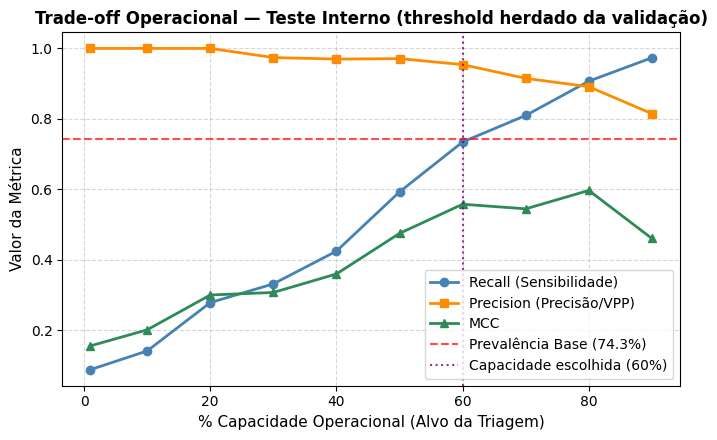

In [ ]:
fig, ax = plt.subplots(figsize=(7, 4.5))

x = curve_test["pct"] * 100
ax.plot(x, curve_test["recall"],    "o-", label="Recall (Sensibilidade)", color="steelblue", linewidth=2)
ax.plot(x, curve_test["precision"], "s-", label="Precision (Precisão/VPP)", color="darkorange", linewidth=2)
ax.plot(x, curve_test["MCC"],       "^-", label="MCC",       color="seagreen", linewidth=2)

ax.axhline(y_dep_test.mean(), ls="--", color="red", alpha=0.7,
           label=f"Prevalência Base ({y_dep_test.mean()*100:.1f}%)")
ax.axvline(cap_escolhida * 100, ls=":", color="purple", alpha=0.8,
           label=f"Capacidade escolhida ({cap_escolhida*100:.0f}%)")

ax.set_xlabel("% Capacidade Operacional (Alvo da Triagem)", fontsize=11)
ax.set_ylabel("Valor da Métrica", fontsize=11)
ax.set_title("Trade-off Operacional — Teste Interno (threshold herdado da validação)",
             fontsize=12, fontweight="bold")
ax.grid(True, linestyle="--", alpha=0.5)
ax.legend(loc="lower right")
plt.tight_layout()
plt.show()

### NNT — Capacidade para achar 1 deprimido

In [ ]:
prior = y_dep_test.mean()
nnt_random = 1 / prior

print(f"NNT se encaminhar aleatoriamente: {nnt_random:.2f}")
print(f"NNT do modelo em cada capacidade (threshold herdado da validação):")
print(curve_test[["pct", "NNT"]].assign(
    pct=lambda d: (d["pct"] * 100).round(0).astype(int).astype(str) + "%",
    NNT=lambda d: d["NNT"].round(2),
).to_string(index=False))

ponto_teste = curve_test[np.isclose(curve_test["pct"], cap_escolhida)].iloc[0]
print(f"\nNNT no TESTE, capacidade {cap_escolhida:.0%}: {ponto_teste['NNT']:.2f}")
print(f"Recall no TESTE, capacidade {cap_escolhida:.0%}: {ponto_teste['recall']:.3f}")

curve_test_plot = curve_test.copy()
curve_test_plot["gain_per_nnt"] = curve_test_plot["recall"] / curve_test_plot["NNT"]
best_op = curve_test_plot.loc[curve_test_plot["gain_per_nnt"].idxmax()]
print(f"\n(Descritivo) Melhor razão recall/NNT no teste: "
      f"capacidade={best_op['pct']*100:.0f}% "
      f"(recall={best_op['recall']:.2f}, NNT={best_op['NNT']:.2f})")

NNT se encaminhar aleatoriamente: 1.35
NNT do modelo em cada capacidade (threshold herdado da validação):
pct  NNT
 1% 1.00
10% 1.00
20% 1.00
30% 1.03
40% 1.03
50% 1.03
60% 1.05
70% 1.09
80% 1.12
90% 1.23

NNT no TESTE, capacidade 60%: 1.05
Recall no TESTE, capacidade 60%: 0.735

(Descritivo) Melhor razão recall/NNT no teste: capacidade=80% (recall=0.91, NNT=1.12)


### Curvas de treino/validação

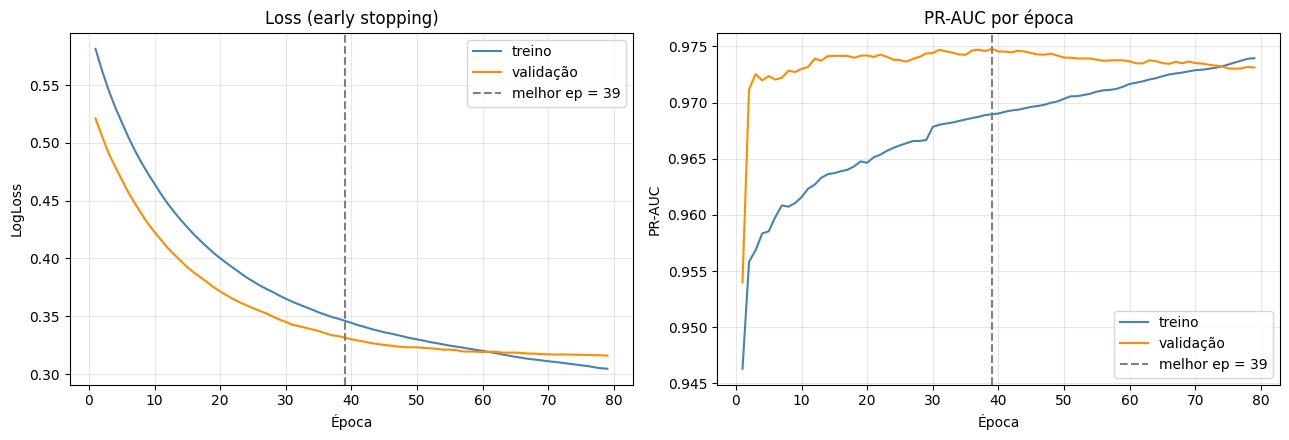

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
ep_axis = np.arange(1, len(hist["val_loss"]) + 1)

axes[0].plot(ep_axis, hist["train_loss"], label="treino", color="steelblue")
axes[0].plot(ep_axis, hist["val_loss"],   label="validação", color="darkorange")
axes[0].axvline(best_epoch, ls="--", color="gray", label=f"melhor ep = {best_epoch}")
axes[0].set_xlabel("Época"); axes[0].set_ylabel("LogLoss")
axes[0].set_title("Loss (early stopping)"); axes[0].legend(); axes[0].grid(alpha=0.3)

axes[1].plot(ep_axis, hist["train_auprc"], label="treino", color="steelblue")
axes[1].plot(ep_axis, hist["val_auprc"],   label="validação", color="darkorange")
axes[1].axvline(best_epoch, ls="--", color="gray", label=f"melhor ep = {best_epoch}")
axes[1].set_xlabel("Época"); axes[1].set_ylabel("PR-AUC")
axes[1].set_title("PR-AUC por época"); axes[1].legend(); axes[1].grid(alpha=0.3)

plt.tight_layout(); plt.show()

### Diagrama de Confiabilidade

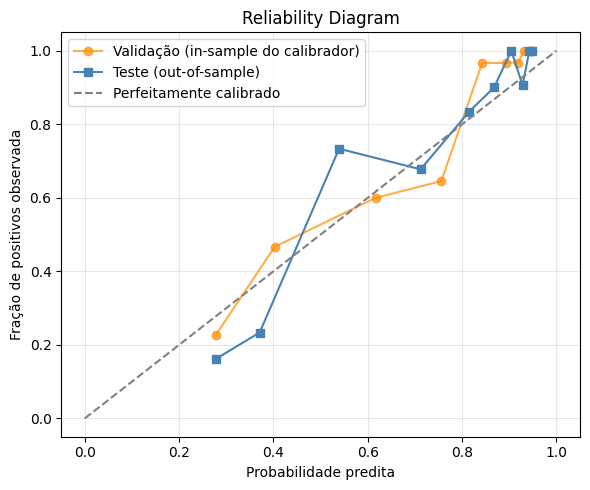

Gap médio (val):   +0.0310
Gap médio (teste): +0.0141


In [ ]:
prob_true_val, prob_pred_val = calibration_curve(y_dep_val, p_val, n_bins=10, strategy="quantile")
prob_true_te,  prob_pred_te  = calibration_curve(y_dep_test, p_test, n_bins=10, strategy="quantile")

fig, ax = plt.subplots(figsize=(6, 5))
ax.plot(prob_pred_val, prob_true_val, "o-", label="Validação (in-sample do calibrador)",
        color="darkorange", alpha=0.7)
ax.plot(prob_pred_te,  prob_true_te,  "s-", label="Teste (out-of-sample)", color="steelblue")
ax.plot([0, 1], [0, 1], "--", label="Perfeitamente calibrado", color="gray")
ax.set_xlabel("Probabilidade predita"); ax.set_ylabel("Fração de positivos observada")
ax.set_title("Reliability Diagram"); ax.legend(); ax.grid(alpha=0.3)
plt.tight_layout(); plt.show()

print("Gap médio (val):   {:+.4f}".format(np.mean(prob_true_val - prob_pred_val)))
print("Gap médio (teste): {:+.4f}".format(np.mean(prob_true_te  - prob_pred_te)))

### Matriz de Confusão (teste)

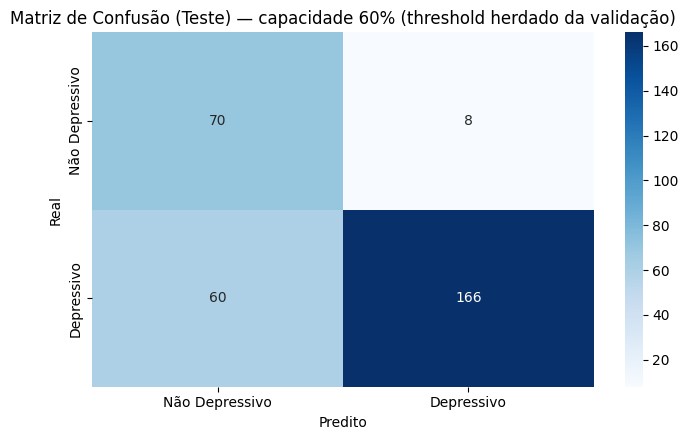

In [ ]:
cm = confusion_matrix(y_dep_test, yhat)
fig, ax = plt.subplots(figsize=(7, 4.5))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", ax=ax,
            xticklabels=["Não Depressivo", "Depressivo"],
            yticklabels=["Não Depressivo", "Depressivo"])
ax.set_title(
    f"Matriz de Confusão (Teste) — capacidade {cap_escolhida:.0%} "
    f"(threshold herdado da validação)"
)
ax.set_xlabel("Predito"); ax.set_ylabel("Real")
plt.tight_layout(); plt.show()

### Classificação das Features

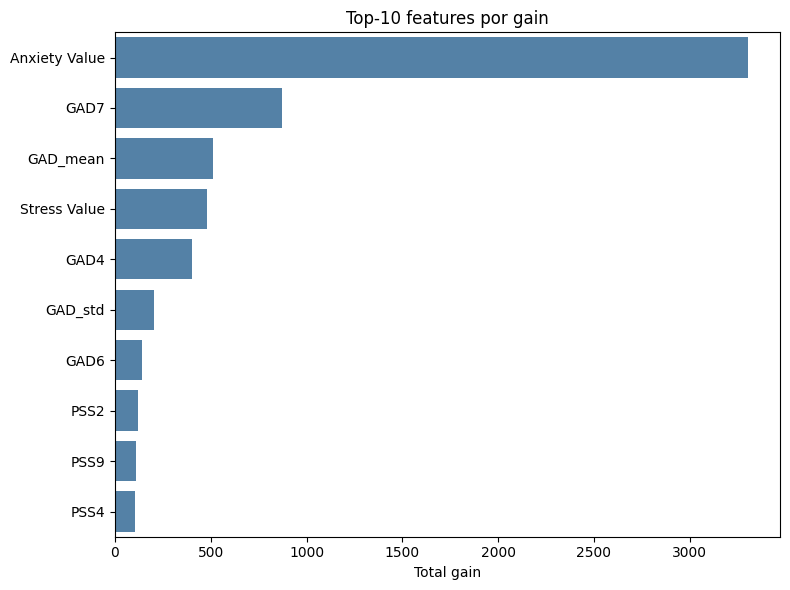

      feature    gain
Anxiety Value 3305.34
         GAD7  873.59
     GAD_mean  509.67
 Stress Value  483.30
         GAD4  401.07
      GAD_std  204.57
         GAD6  143.85
         PSS2  122.85
         PSS9  111.51
         PSS4  107.37


In [ ]:
cat_names = preprocess.named_transformers_["cat"].get_feature_names_out(FEAT_CAT)
feature_names_all = list(FEAT_NUM) + list(cat_names)

booster = model.get_booster()
gain = booster.get_score(importance_type="total_gain")
imp = pd.DataFrame({
    "feature": [feature_names_all[int(k[1:])] if k.startswith("f") else k for k in gain.keys()],
    "gain":    list(gain.values()),
}).sort_values("gain", ascending=False).head(10)

fig, ax = plt.subplots(figsize=(8, 6))
sns.barplot(data=imp, y="feature", x="gain", ax=ax, color="steelblue")
ax.set_title("Top-10 features por gain")
ax.set_xlabel("Total gain"); ax.set_ylabel("")
plt.tight_layout(); plt.show()
print(imp.round(2).to_string(index=False))

assert not any("PHQ" in f for f in imp["feature"]), "PHQ nas importâncias!"
assert not any(f in {"Depression Value", "dep_y", "Depression Label"} for f in imp["feature"])

## 14. Baselines e comparação

In [ ]:
dummy_clf = DummyClassifier(strategy="most_frequent").fit(X_train, y_dep_train)
dummy_probs = dummy_clf.predict_proba(X_test)[:, 1]

tree_clf = DecisionTreeClassifier(max_depth=5, random_state=SEED).fit(X_train, y_dep_train)
tree_probs = tree_clf.predict_proba(X_test)[:, 1]

comparacao = pd.DataFrame({
    "Modelo": [
        "Dummy (most_frequent)",
        "Árvore de Decisão (depth=5)",
        "XGBoost calibrado (demo + PSS + GAD)",
    ],
    "PR-AUC": [
        average_precision_score(y_dep_test, dummy_probs),
        average_precision_score(y_dep_test, tree_probs),
        average_precision_score(y_dep_test, p_test),
    ],
    "ROC-AUC": [
        roc_auc_score(y_dep_test, dummy_probs) if len(set(y_dep_test)) > 1 else np.nan,
        roc_auc_score(y_dep_test, tree_probs),
        roc_auc_score(y_dep_test, p_test),
    ],
    "Brier": [
        brier_score_loss(y_dep_test, dummy_probs),
        brier_score_loss(y_dep_test, tree_probs),
        brier_score_loss(y_dep_test, p_test),
    ],
})
print(comparacao.round(4).to_string(index=False))

delta_pr  = comparacao.loc[2, "PR-AUC"]  - comparacao.loc[1, "PR-AUC"]
delta_roc = comparacao.loc[2, "ROC-AUC"] - comparacao.loc[1, "ROC-AUC"]
print(f"\nΔ XGB − Árvore:  PR-AUC {delta_pr:+.4f} | ROC-AUC {delta_roc:+.4f}")

                              Modelo  PR-AUC  ROC-AUC  Brier
               Dummy (most_frequent)  0.7434   0.5000 0.2566
         Árvore de Decisão (depth=5)  0.9320   0.8549 0.1325
XGBoost calibrado (demo + PSS + GAD)  0.9587   0.8950 0.1115

Δ XGB − Árvore:  PR-AUC +0.0267 | ROC-AUC +0.0401


## 15. Validação Externa

### Funções de parsing

In [ ]:
LIKERT_PATTERN = re.compile(r"^\s*([0-9])\s*=")

def parse_likert(x):
    if pd.isna(x):
        return np.nan
    if isinstance(x, (int, float, np.integer, np.floating)):
        v = float(x)
        return v if 0 <= v <= 4 else np.nan
    s = str(x).strip().lower()

    if re.fullmatch(r"[0-4]", s):
        return float(s)

    m = LIKERT_PATTERN.match(s)
    if m:
        return float(m.group(1))
    if "nearly every day" in s or "প্রায় প্রতিদিন" in s:
        return 4.0
    if "more than half" in s or "অর্ধেকের বেশি" in s:
        return 3.0
    if "several days" in s or "বেশ কয়েক দিন" in s:
        return 2.0
    if "not at all" in s or "মোটেই না" in s:
        return 0.0
    if "always" in s:
        return 4.0
    if "often" in s:
        return 3.0
    if "sometimes" in s:
        return 2.0
    if "rarely" in s:
        return 1.0
    if "never" in s:
        return 0.0
    return np.nan


def parse_yes_no(x):
    if pd.isna(x):
        return np.nan
    s = str(x).strip().lower()
    if s.startswith("yes") or s.startswith("হ্যাঁ"):
        return 1.0
    if s.startswith("no") or s.startswith("না"):
        return 0.0
    return np.nan


def parse_gender(x):
    if pd.isna(x):
        return np.nan
    s = str(x).lower()
    if "female" in s or "মহিলা" in s:
        return "Female"
    if "male" in s or "পুরুষ" in s:
        return "Male"
    return "Other"


def parse_age(x):
    if pd.isna(x):
        return np.nan
    try:
        a = float(x)
    except (ValueError, TypeError):
        return np.nan
    if a < 18:
        return "Below 18"
    if a <= 22:
        return "18-22"
    if a <= 26:
        return "23-26"
    if a <= 30:
        return "27-30"
    return "Above 30"


def parse_education_to_year(x):
    if pd.isna(x):
        return np.nan
    s = str(x).lower()
    if "মাস্টার্স" in s or "masters" in s:
        return "Other"
    if "ব্যচেলর" in s or "bachelor" in s:
        return "Fourth Year or Equivalent"
    if "এইচএসসি" in s or "hsc" in s:
        return "Second Year or Equivalent"
    if "এসএসসি" in s or "ssc" in s:
        return "First Year or Equivalent"
    return "Other"


def parse_cgpa_band(x):
    if pd.isna(x):
        return np.nan
    try:
        c = float(x)
    except (ValueError, TypeError):
        return np.nan
    if c < 2.50:
        return "Below 2.50"
    if c < 3.00:
        return "2.50 - 2.99"
    if c < 3.40:
        return "3.00 - 3.39"
    if c < 3.80:
        return "3.40 - 3.79"
    return "3.80 - 4.00"


def is_student(row):
    edu = str(row.get("education", "")).lower()
    prof = str(row.get("profession", "")).lower()
    jog = str(row.get("job_type", "")).lower()
    keywords = ["bachelor", "masters", "student", "graduate", "examine",
                "ব্যচেলর", "মাস্টার্স", "ছাত্র", "গ্র্যাজুয়েট", "পরীক্ষার্থী"]
    haystack = edu + " " + prof + " " + jog
    return any(k in haystack for k in keywords)

### Harmonização das features + filtro por estudantes

In [ ]:
mask_student = ext_raw.apply(is_student, axis=1)
print(f"Linhas no Combined Dataset: {len(ext_raw)}")
print(f"Linhas identificadas como estudantes/graduados: {int(mask_student.sum())} "
      f"({mask_student.mean()*100:.1f}%)")

ext_students = ext_raw[mask_student].reset_index(drop=True)
print(f"Subconjunto de estudantes: {len(ext_students)} linhas")

ext = pd.DataFrame(index=ext_students.index)
ext["Age"]           = ext_students["age"].apply(parse_age)
ext["Gender"]        = ext_students["gender"].apply(parse_gender)
ext["Academic Year"] = ext_students["education"].apply(parse_education_to_year)
ext["Current CGPA"]  = ext_students["bachelor_cgpa"].apply(parse_cgpa_band)
ext["Waiver"]        = ext_students["financial_stress"].apply(
    lambda x: "Yes" if str(x).lower().startswith(("high", "very", "অনেক")) else "No"
)
ext["University"]    = "__UNKNOWN__"
ext["Department"]    = "__UNKNOWN__"

pss_map = {
    "PSS1":  ("pss10_upset",           False),
    "PSS2":  ("pss10_uncontrol",       False),
    "PSS3":  ("pss10_stressed",        False),
    "PSS4":  ("pss10_confident_rev",   True),
    "PSS5":  ("pss10_going_way_rev",   True),
    "PSS6":  ("pss10_cope",            False),
    "PSS7":  ("pss10_irritations_rev", True),
    "PSS8":  ("pss10_on_top_rev",      True),
    "PSS9":  ("pss10_angered",         False),
    "PSS10": ("pss10_difficulties",    False),
}
for target, (src, reverse) in pss_map.items():
    v = ext_students[src].apply(parse_likert)
    ext[target] = (4 - v) if reverse else v

gad_map = {
    "GAD1": "gad7_nervous", "GAD2": "gad7_worry_control", "GAD3": "gad7_excess_worry",
    "GAD4": "gad7_relax", "GAD5": "gad7_restless", "GAD6": "gad7_irritable",
    "GAD7": "gad7_afraid",
}
for target, src in gad_map.items():
    ext[target] = ext_students[src].apply(parse_likert)

phq_map = {
    "PHQ1": "phq9_interest", "PHQ2": "phq9_depressed", "PHQ3": "phq9_sleep",
    "PHQ4": "phq9_tired", "PHQ5": "phq9_appetite", "PHQ6": "phq9_self_bad",
    "PHQ7": "phq9_concentrate", "PHQ8": "phq9_movement", "PHQ9": "phq9_suicidal",
}
for target, src in phq_map.items():
    ext[target] = ext_students[src].apply(parse_likert)

cov = ext.notna().mean().round(3).sort_values()
print("\nCobertura das colunas harmonizadas (fração não-nula):")
print(cov.to_string())

Linhas no Combined Dataset: 9984
Linhas identificadas como estudantes/graduados: 5502 (55.1%)
Subconjunto de estudantes: 5502 linhas

Cobertura das colunas harmonizadas (fração não-nula):
Current CGPA     0.630
GAD2             0.736
GAD3             0.751
PSS2             0.751
PHQ6             0.751
PSS7             0.754
PHQ4             0.756
PSS8             0.757
PHQ8             0.757
PHQ2             0.757
PHQ1             0.758
GAD1             0.758
PSS9             0.758
PSS5             0.759
PHQ7             0.759
PSS10            0.759
PHQ5             0.760
GAD6             0.760
GAD7             0.761
PSS1             0.761
PSS3             0.764
GAD4             0.764
PHQ3             0.764
PSS6             0.764
PHQ9             0.764
GAD5             0.765
PSS4             0.768
Academic Year    1.000
University       1.000
Department       1.000
Gender           1.000
Waiver           1.000
Age              1.000


### Filtragem + alvo proxy + imputação

**Regra:** mantemos apenas linhas com **PHQ-9 completo** (alvo). PSS/GAD faltantes
são imputados com medianas do treino interno.

In [ ]:
PSS_ITEMS_EXT = [f"PSS{i}" for i in range(1, 11)]
GAD_ITEMS_EXT = [f"GAD{i}" for i in range(1, 8)]
PHQ_ITEMS_EXT = [f"PHQ{i}" for i in range(1, 10)]

mask_pss = ext[PSS_ITEMS_EXT].notna().all(axis=1)
mask_gad = ext[GAD_ITEMS_EXT].notna().all(axis=1)
mask_phq = ext[PHQ_ITEMS_EXT].notna().all(axis=1)
mask_all = mask_pss & mask_gad & mask_phq
usable   = mask_phq

print(f"Linhas (após filtro de estudantes): {len(ext)}")
print(f"com PSS-10 completo: {int(mask_pss.sum())}")
print(f"com GAD-7 completo:  {int(mask_gad.sum())}")
print(f"com PHQ-9 completo:  {int(mask_phq.sum())}")
print(f"com PSS+GAD+PHQ completos: {int(mask_all.sum())} ({mask_all.mean()*100:.1f}%)")

ext = ext.loc[usable].copy().reset_index(drop=True)
if len(ext) == 0:
    raise RuntimeError("Nenhuma linha do externo possui PHQ-9 completo.")

ext["PHQ_total"] = ext[PHQ_ITEMS_EXT].sum(axis=1)
ext["dep_y_proxy"] = (ext["PHQ_total"] >= 10).astype(int)

for c in PSS_ITEMS_EXT + GAD_ITEMS_EXT:
    if ext[c].isna().any():
        ext[c] = ext[c].fillna(train_eng[c].median())

ext["Stress Value"]  = ext[PSS_ITEMS_EXT].sum(axis=1)
ext["Anxiety Value"] = ext[GAD_ITEMS_EXT].sum(axis=1)

print(f"\nPHQ_total — estatísticas:")
print(ext["PHQ_total"].describe().round(2).to_string())
print(f"\nPrevalência do alvo proxy (PHQ≥10): {ext['dep_y_proxy'].mean():.3f} "
      f"({int(ext['dep_y_proxy'].sum())}/{len(ext)})")
print(f"Prevalência do alvo treinado (Depression Label bin): "
      f"{df['dep_y'].mean():.3f} ({int(df['dep_y'].sum())}/{len(df)})")

TRAIN_MODES = {
    "University": train["University"].mode().iloc[0],
    "Department": train["Department"].mode().iloc[0],
    "Gender":     train["Gender"].mode().iloc[0],
    "Waiver":     train["Waiver"].mode().iloc[0],
}
for col, mode_val in TRAIN_MODES.items():
    ext[col] = ext[col].fillna(mode_val)

before = len(ext)
ext = ext.dropna(subset=["Age", "Current CGPA", "Academic Year"]).reset_index(drop=True)
print(f"Após filtro demográfico: {len(ext)} (removidas {before - len(ext)})")

ext_eng = build_features(add_ordinals(ext))

missing_cols = [c for c in FEAT_ALL if c not in ext_eng.columns]
if missing_cols:
    raise AssertionError(f"Features ausentes no externo: {missing_cols}")

leak_ext = [c for c in FEAT_ALL if c in FORBIDDEN or c.startswith("PHQ")]
assert not leak_ext, f"VAZAMENTO no externo: {leak_ext}"

Linhas (após filtro de estudantes): 5502
com PSS-10 completo: 865
com GAD-7 completo:  1266
com PHQ-9 completo:  964
com PSS+GAD+PHQ completos: 141 (2.6%)

PHQ_total — estatísticas:
count    964.00
mean       4.28
std        4.46
min        0.00
25%        2.00
50%        3.00
75%        4.00
max       20.00

Prevalência do alvo proxy (PHQ≥10): 0.117 (113/964)
Prevalência do alvo treinado (Depression Label bin): 0.726 (1473/2028)
Após filtro demográfico: 734 (removidas 230)


### Aplicando Modelo

In [ ]:
X_ext = preprocess.transform(ext_eng[FEAT_ALL])
p_ext = model.predict_proba(X_ext)[:, 1]
y_ext = ext["dep_y_proxy"].values

print(f"\nDimensões do externo pré-processado: {X_ext.shape}")
print(f"Previsões: min={p_ext.min():.3f} | max={p_ext.max():.3f} | média={p_ext.mean():.3f}")
print(f"Distribuição real do alvo proxy: {np.bincount(y_ext)}")

tem_duas_classes = (len(np.unique(y_ext)) == 2)


Dimensões do externo pré-processado: (734, 76)
Previsões: min=0.219 | max=0.932 | média=0.380
Distribuição real do alvo proxy: [679  55]


### Relatório de classificação

In [ ]:
if tem_duas_classes:
    roc_auc_ext  = roc_auc_score(y_ext, p_ext)
    pr_auc_ext   = average_precision_score(y_ext, p_ext)
    brier_ext    = brier_score_loss(y_ext, p_ext)
    ece_ext      = ece(y_ext, p_ext)
    spearman_ext = spearmanr(p_ext, ext["PHQ_total"]).correlation
else:
    roc_auc_ext = pr_auc_ext = brier_ext = ece_ext = spearman_ext = np.nan

print("=== Relatório de classificação no dataset externo ===")
print(f"  ROC-AUC                     : {roc_auc_ext:.4f}")
print(f"  PR-AUC                      : {pr_auc_ext:.4f}")
print(f"  Spearman(p, PHQ_total)      : {spearman_ext:.4f}")
print(f"  Brier                       : {brier_ext:.4f}")
print(f"  ECE                         : {ece_ext:.4f}")

=== Relatório de classificação no dataset externo ===
  ROC-AUC                     : 0.9881
  PR-AUC                      : 0.9651
  Spearman(p, PHQ_total)      : 0.2529
  Brier                       : 0.1181
  ECE                         : 0.3201


### Threshold Fixo

In [ ]:
yhat_ext_fixo = (p_ext >= THR_FIXO).astype(int)

print(f"=== Threshold fixo a priori (análogo a PHQ-9 >= 10) ===")
print(f"  Threshold                           : {THR_FIXO:.2f}")
print(f"  Positivos preditos no externo       : {int(yhat_ext_fixo.sum())}/{len(yhat_ext_fixo)} "
      f"({yhat_ext_fixo.mean()*100:.1f}%)")
print(f"  Prevalência do alvo proxy (y_ext)   : {y_ext.mean()*100:.1f}%")

if yhat_ext_fixo.sum() > 0 and tem_duas_classes:
    tp_f = int(((yhat_ext_fixo == 1) & (y_ext == 1)).sum())
    fp_f = int(((yhat_ext_fixo == 1) & (y_ext == 0)).sum())
    fn_f = int(((yhat_ext_fixo == 0) & (y_ext == 1)).sum())
    tn_f = int(((yhat_ext_fixo == 0) & (y_ext == 0)).sum())
    mcc_f  = matthews_corrcoef(y_ext, yhat_ext_fixo)
    prec_f = tp_f / max(tp_f + fp_f, 1)
    rec_f  = tp_f / max(tp_f + fn_f, 1)
    nnt_f  = (tp_f + fp_f) / max(tp_f, 1)
    print(f"  TP={tp_f} | FP={fp_f} | FN={fn_f} | TN={tn_f}")
    print(f"  Recall    : {rec_f:.4f}")
    print(f"  Precision : {prec_f:.4f}")
    print(f"  MCC       : {mcc_f:.4f}")
    print(f"  NNT       : {nnt_f:.2f}")
else:
    print("  Nenhum positivo classificado com threshold fixo.")

# Referência descritiva: threshold herdado (sem correção), apenas para comparação
yhat_ext_herdado = (p_ext >= best_thr_operacional).astype(int)
print(f"\n[Referência descritiva] Threshold herdado ({best_thr_operacional:.4f}) SEM correção:")
print(f"  Positivos preditos: {int(yhat_ext_herdado.sum())}/{len(yhat_ext_herdado)} "
      f"({yhat_ext_herdado.mean()*100:.1f}%)")
if yhat_ext_herdado.sum() > 0 and tem_duas_classes:
    print(f"  MCC: {matthews_corrcoef(y_ext, yhat_ext_herdado):.4f}")

=== Threshold fixo a priori (análogo a PHQ-9 >= 10) ===
  Threshold                           : 0.50
  Positivos preditos no externo       : 84/734 (11.4%)
  Prevalência do alvo proxy (y_ext)   : 7.5%
  TP=54 | FP=30 | FN=1 | TN=649
  Recall    : 0.9818
  Precision : 0.6429
  MCC       : 0.7755
  NNT       : 1.56

[Referência descritiva] Threshold herdado (0.8023) SEM correção:
  Positivos preditos: 45/734 (6.1%)
  MCC: 0.8979


### Diagnostico: Threshold operacional

recall/precision/NNT/MCC no dataset externo em função da **capacidade k%**
(top-k de `p_ext`).

In [ ]:
if tem_duas_classes:
    CAPS_EXT = [0.05, 0.10, 0.15, 0.20, 0.30, 0.40, 0.50, 0.60]
    rows_ext = []
    prior_ext = y_ext.mean()
    for cap in CAPS_EXT:
        thr_ext = np.quantile(p_ext, 1 - cap)
        yhat_ext = (p_ext >= thr_ext).astype(int)
        tp = int(((yhat_ext == 1) & (y_ext == 1)).sum())
        fp = int(((yhat_ext == 1) & (y_ext == 0)).sum())
        fn = int(((yhat_ext == 0) & (y_ext == 1)).sum())
        tn = int(((yhat_ext == 0) & (y_ext == 0)).sum())
        rec = tp / max(tp + fn, 1)
        prec = tp / max(tp + fp, 1)
        mcc = matthews_corrcoef(y_ext, yhat_ext) if len(np.unique(yhat_ext)) > 1 else np.nan
        nnt = (tp + fp) / max(tp, 1)
        lift = prec / prior_ext if prior_ext > 0 else np.nan
        rows_ext.append({
            "capacidade": cap, "threshold_p_ext": thr_ext,
            "n_flagged": int(yhat_ext.sum()),
            "recall": rec, "precision": prec, "MCC": mcc,
            "NNT": nnt, "lift": lift,
            "TP": tp, "FP": fp, "FN": fn, "TN": tn,
        })
    ext_op = pd.DataFrame(rows_ext)
    print("=== Cenário threshold operacional no externo ===")
    print(ext_op.round(4).to_string(index=False))
    print()
    print(f"Prevalência externa (descritiva): {prior_ext:.3f}")
else:
    ext_op = None
    print("Cenário operacional não calculado (classe única no externo).")

=== Cenário threshold operacional no externo ===
 capacidade  threshold_p_ext  n_flagged  recall  precision    MCC     NNT    lift  TP  FP  FN  TN
       0.05           0.8412         37  0.6727     1.0000 0.8095  1.0000 13.3455  37   0  18 679
       0.10           0.5848         74  0.9455     0.7027 0.7984  1.4231  9.3779  52  22   3 657
       0.20           0.4238        147  0.9818     0.3673 0.5558  2.7222  4.9024  54  93   1 586
       0.30           0.3539        220  0.9818     0.2455 0.4237  4.0741  3.2757  54 166   1 513
       0.40           0.3316        297  0.9818     0.1818 0.3347  5.5000  2.4264  54 243   1 436
       0.50           0.3221        368  0.9818     0.1467 0.2735  6.8148  1.9583  54 314   1 365
       0.60           0.3131        441  1.0000     0.1247 0.2320  8.0182  1.6644  55 386   0 293
       0.70           0.3031        514  1.0000     0.1070 0.1862  9.3455  1.4280  55 459   0 220
       0.80           0.2914        588  1.0000     0.0935 0.1418 10.

### Diagnóstico: EM de Saerens e covariate shift (KLIEP)

1. **EM de Saerens**: se converge para π ≈ `PI_EXT_A_PRIORI`, a premissa
   de label shift está validada. Se não, há domain shift além do prior.
2. **KLIEP** (density ratio treino vs. externo): mede se $P(x)$ mudou.
   Peso alto/heterogêneo ⇒ covariate shift forte ⇒ não confiar em Saerens.

In [ ]:
pi_train = y_dep_val.mean()

p_ext_em, pi_ext_em, n_iter_em, convergiu_em = prior_shift_correction_em(
    p_ext, pi_train=pi_train
)
print("=== Diagnóstico 1: EM de Saerens ===")
print(f"  π_train              : {pi_train:.4f}")
print(f"  π_ext estimado (EM)  : {pi_ext_em:.4f}  "
      f"({'convergiu' if convergiu_em else 'NÃO convergiu'} em {n_iter_em} iter)")
if pi_ext_em < 0.01:
    print("  → π_ext ≈ 0: distribuição de p_ext praticamente sem massa acima de 0.")
    print("    Saerens colapsaria todos os positivos. Premissa de label shift FALSA.")
else:
    print(f"  → π_ext = {pi_ext_em:.4f}: comparar com prevalência esperada do PHQ-9.")

X_domain = np.vstack([X_train, X_ext])
y_domain = np.concatenate([np.zeros(len(X_train)), np.ones(len(X_ext))])
clf_domain = LogisticRegression(max_iter=2000, class_weight="balanced", random_state=SEED)
proba_domain = cross_val_predict(
    clf_domain, X_domain, y_domain, cv=5, method="predict_proba"
)[:, 1]
auc_domain = roc_auc_score(y_domain, proba_domain)

w_ext = proba_domain[len(X_train):]
eps = 1e-6
w_ext_ratio = w_ext / np.clip(1 - w_ext, eps, None)
w_ext_ratio = np.clip(w_ext_ratio, 0, np.quantile(w_ext_ratio, 0.99))

print("\n=== Diagnóstico 2: KLIEP ===")
print(f"  AUC do classificador de domínio: {auc_domain:.4f}")
print(f"  w(x) externo — stats: min={w_ext_ratio.min():.3f} | "
      f"mediana={np.median(w_ext_ratio):.3f} | max={w_ext_ratio.max():.3f}")
print(f"  Coef. de variação de w(x): {w_ext_ratio.std() / max(w_ext_ratio.mean(), eps):.3f}")
if auc_domain > 0.9:
    print("  → Covariate shift SEVERO. P(x) estável,")
else:
    print("  → Covariate shift moderado. Verificar estabilidade dos thresholds.")

=== Diagnóstico 1: EM de Saerens (NÃO usado para threshold) ===
  π_train              : 0.7829
  π_ext estimado (EM)  : 0.0000  (convergiu em 12 iter)
  → π_ext ≈ 0: distribuição de p_ext praticamente sem massa acima de 0.
    Saerens colapsaria todos os positivos. Premissa de label shift FALSA.

=== Diagnóstico 2: KLIEP (covariate shift) ===
  AUC do classificador de domínio: 0.9999
  w(x) externo — stats: min=0.231 | mediana=1604.054 | max=151794.008
  Coef. de variação de w(x): 2.243
  → Covariate shift SEVERO. Métodos que assumem P(x) estável (Saerens,
    quantil herdado) são inadequados. Threshold fixo a priori é mais honesto.


### Distribuição de `p_ext` (bruto vs. corrigido)

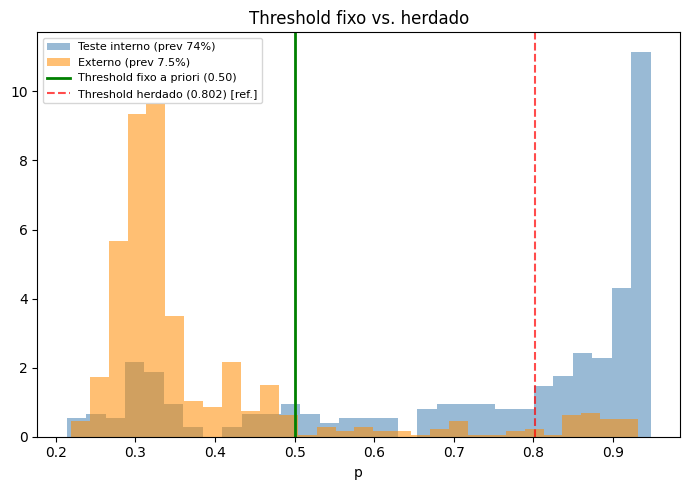

Fração flagada — threshold fixo 0.50 : 0.114
Fração flagada — threshold herdado   : 0.061
Prevalência proxy (y_ext)            : 0.075


In [ ]:
fig, ax = plt.subplots(figsize=(7, 5))

ax.hist(p_test, bins=30, alpha=0.55, label=f"Teste interno (prev {y_dep_test.mean():.0%})",
             color="steelblue", density=True)
ax.hist(p_ext,  bins=30, alpha=0.55, label=f"Externo (prev {y_ext.mean():.1%})",
             color="darkorange", density=True)
ax.axvline(THR_FIXO, ls="-", color="green", linewidth=2,
                label=f"Threshold fixo a priori ({THR_FIXO:.2f})")
ax.axvline(best_thr_operacional, ls="--", color="red", alpha=0.7,
                label=f"Threshold herdado ({best_thr_operacional:.3f}) [ref.]")
ax.set_title("Threshold fixo vs. herdado")
ax.set_xlabel("p"); axes[0].set_ylabel("Densidade")
ax.legend(fontsize=8); axes[0].grid(alpha=0.3)

plt.tight_layout(); plt.show()

print(f"Fração flagada — threshold fixo 0.50 : {yhat_ext_fixo.mean():.3f}")
print(f"Fração flagada — threshold herdado   : {yhat_ext_herdado.mean():.3f}")
print(f"Prevalência proxy (y_ext)            : {y_ext.mean():.3f}")

### Diagrama de Confiabilidade no Dataset Externo

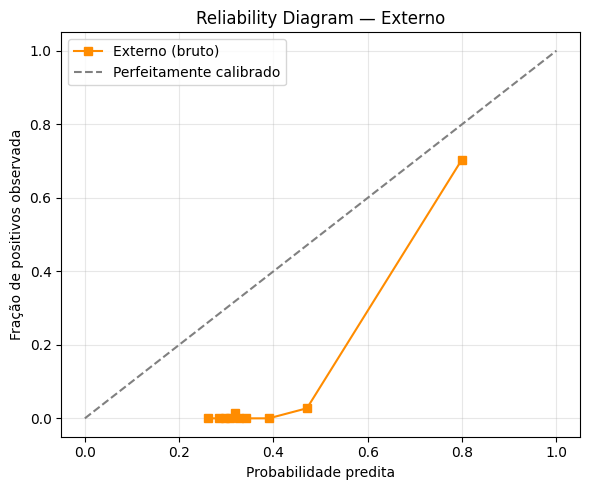

Gap médio (ext): -0.3052


In [ ]:
if tem_duas_classes:
    prob_true_ext, prob_pred_ext = calibration_curve(y_ext, p_ext, n_bins=10, strategy="quantile")
    fig, ax = plt.subplots(figsize=(6, 5))
    ax.plot(prob_pred_ext, prob_true_ext, "s-", label="Externo (bruto)", color="darkorange")
    ax.plot([0, 1], [0, 1], "--", color="gray", label="Perfeitamente calibrado")
    ax.set_xlabel("Probabilidade predita"); ax.set_ylabel("Fração de positivos observada")
    ax.set_title("Reliability Diagram — Externo"); ax.legend(); ax.grid(alpha=0.3)
    plt.tight_layout(); plt.show()
    print(f"Gap médio (ext): {np.mean(prob_true_ext - prob_pred_ext):+.4f}")
else:
    print("Reliability diagram não pode ser gerado (classe única).")

### Matriz de confusão externa (threshold fixo)

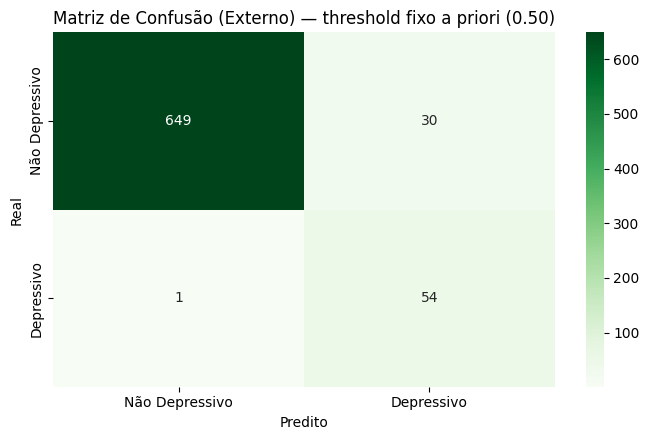

In [ ]:
if tem_duas_classes and yhat_ext_fixo.sum() > 0:
    cm_ext = confusion_matrix(y_ext, yhat_ext_fixo)
    fig, ax = plt.subplots(figsize=(7, 4.5))
    sns.heatmap(cm_ext, annot=True, fmt="d", cmap="Greens", ax=ax,
                xticklabels=["Não Depressivo", "Depressivo"],
                yticklabels=["Não Depressivo", "Depressivo"])
    ax.set_title(f"Matriz de Confusão (Externo) — threshold fixo a priori ({THR_FIXO:.2f})")
    ax.set_xlabel("Predito"); ax.set_ylabel("Real")
    plt.tight_layout(); plt.show()
else:
    print("Matriz externa não gerada (classe única ou zero positivos com threshold fixo).")

## 16. Auditoria final

In [ ]:
assert len(df) == N_ORIGINAL, f"df tem {len(df)} linhas, esperado {N_ORIGINAL}."

forbidden_em_feat = [c for c in FEAT_ALL if c in FORBIDDEN or c.startswith("PHQ")]
assert not forbidden_em_feat, f"VAZAMENTO em FEAT_ALL: {forbidden_em_feat}"
assert not any("PHQ" in f for f in imp["feature"]), "PHQ nas importâncias!"

def _k(d): return set(d["group_key"].values)
ov = {
    "train∩val":  len(_k(train) & _k(val)),
    "train∩test": len(_k(train) & _k(test)),
    "val∩test":   len(_k(val)   & _k(test)),
}
assert all(v == 0 for v in ov.values()), f"Overlap entre splits: {ov}"

thr_esperado = float(np.quantile(p_val, 1 - cap_escolhida))
assert np.isclose(best_thr_operacional, thr_esperado), \
    f"Threshold herdado não bate com quantil de p_val: {best_thr_operacional} vs {thr_esperado}"
assert CAPACIDADE_MIN <= cap_escolhida <= CAPACIDADE_MAX, \
    f"Capacidade fora de [{CAPACIDADE_MIN}, {CAPACIDADE_MAX}]: {cap_escolhida}"

# Threshold fixo: NÃO pode depender de nenhum dado do externo
assert THR_FIXO == 0.50, f"THR_FIXO alterado sem justificativa: {THR_FIXO}"
assert isinstance(THR_FIXO, float), "THR_FIXO deve ser float literal."

# Auditoria: threshold fixo não olha para y_ext nem para p_ext
_thr_check = (p_ext >= THR_FIXO).astype(int)
assert np.array_equal(_thr_check, yhat_ext_fixo), \
    "yhat_ext_fixo não é (p_ext >= THR_FIXO) — dependência oculta detectada."

# Proibir variáveis que sugiram otimização de threshold no externo
forbidden_attrs = [
    "curve_ext_otim", "thr_ext_otimizado", "mcc_ext_otimizado",
    "best_thr_ext", "cap_ext_otim",
    "p_ext_corrected", "yhat_ext_corrected",  # prior shift removido
]
for attr in forbidden_attrs:
    assert attr not in globals(), (
        f"Variável '{attr}' existe — resíduo de prior shift ou threshold re-otimizado."
    )

# Diagnósticos podem existir, mas não podem influenciar decisão
assert 'pi_ext_em' in globals(), "Bloco de diagnóstico (EM) não executado."
assert 0 <= pi_ext_em <= 1, f"π_ext estimado pelo EM fora de [0,1]: {pi_ext_em}"
assert 'w_ext_ratio' in globals(), "Bloco de diagnóstico (KLIEP) não executado."
assert np.all(w_ext_ratio >= 0), "w(x) tem valores negativos."
assert np.all(np.isfinite(w_ext_ratio)), "w(x) tem NaN/inf."

# Cenário operacional: thresholds são quantis de p_ext (não de y_ext)
if ext_op is not None:
    assert len(ext_op) > 0, "Cenário operacional vazio."
    for _, row in ext_op.iterrows():
        thr_esperado_op = float(np.quantile(p_ext, 1 - row["capacidade"]))
        assert np.isclose(row["threshold_p_ext"], thr_esperado_op), \
            f"Threshold operacional ({row['capacidade']}) não é quantil de p_ext."
else:
    print("Cenário operacional não calculado (classe única).")

assert len(ext) > 0, "Amostra externa vazia após filtragem."
assert X_ext.shape[1] == X_train.shape[1], \
    f"Dimensionalidade divergente: X_ext={X_ext.shape} vs X_train={X_train.shape}"
assert ((ext["PHQ_total"] >= 10).astype(int) == ext["dep_y_proxy"]).all(), \
    "dep_y_proxy inconsistente com PHQ_total."

for c in PSS_ITEMS_EXT + GAD_ITEMS_EXT + PHQ_ITEMS_EXT:
    v = ext[c].dropna()
    if len(v) == 0:
        continue
    assert v.min() >= 0 and v.max() <= 4, f"{c} fora de [0,4] após parser"

assert np.allclose(ext["Stress Value"],  ext[PSS_ITEMS_EXT].sum(axis=1)), \
    "Stress Value inconsistente com itens PSS."
assert np.allclose(ext["Anxiety Value"], ext[GAD_ITEMS_EXT].sum(axis=1)), \
    "Anxiety Value inconsistente com itens GAD."

leak_ext_audit = [c for c in FEAT_ALL if c in FORBIDDEN or c.startswith("PHQ")]
assert not leak_ext_audit, f"VAZAMENTO no externo: {leak_ext_audit}"